# Master Case Study: Applied Business Statistics & Product Analytics with Python

Welcome to the **Week 8 Master Case Study: Applied Business Statistics & Product Analytics**. In this comprehensive industry assignment, you will step into the role of a **Lead Product Analytics Engineer** at *PulseFlow Analytics*, a fast-growing digital platform.

You have been tasked with auditing the company's core user journey: evaluating telemetry latency distributions, isolating conversion bottlenecks across the onboarding funnel, measuring long-term user retention decay, and running a rigorous statistical evaluation of a major **Homepage Redesign A/B Test (50,000 users)**.

---
### 🎯 Learning Objectives
1. **Descriptive Spread & Skewness Detection**: Quantify distribution spread (Mean, Median, Std, IQR), detect severe skewness using the 20% rule, and normalize heavy-tailed latency/revenue metrics with `np.log1p()`.
2. **Funnel Analytics & Step Drop-off Isolation**: Ingest and deduplicate raw clickstream event logs, calculate step-over-step retention/drop-offs, and segment by device to isolate mobile conversion friction.
3. **Monthly Cohort Retention Analysis**: Construct user cohorts by acquisition Genesis, calculate temporal cohort indices (0 to 6 months), compute retention percentages, and render an annotated Seaborn heatmap.
4. **Two-Sample Experimentation Statistical Evaluation**: Evaluate primary conversion lift using a Two-Sample Proportion Z-Test / Chi-Square test + 95% Confidence Intervals, and evaluate guardrail ARPU metrics using Welch's Two-Sample T-Test.
5. **Experiment Diagnostics & Executive Decision Memo**: Perform Sample Ratio Mismatch (SRM $\chi^2$) checks, isolate novelty bias (Week 1 vs. Week 2), verify segment effects (Simpson's Paradox), and author a structured 1-page executive decision memo using the Minto SCR framework.

---
### 📋 Instructions
- Complete each of the **5 structured tasks** below by filling in the `# TODO` sections.
- Run the **Validation Assertions** provided inside each task cell to verify that your calculations are mathematically and structurally accurate before submission.


## Environment Setup
Import the required libraries for statistical computation, data wrangling, hypothesis testing, and publication-quality visualization.


In [52]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Visualization styling configuration
sns.set_theme(style='whitegrid', palette='mako')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print('✅ Environment initialized with NumPy, Pandas, SciPy.Stats, Matplotlib, and Seaborn.')


✅ Environment initialized with NumPy, Pandas, SciPy.Stats, Matplotlib, and Seaborn.


In [53]:
import os

print(os.getcwd())

# Create data folder at the project root
os.makedirs("../data", exist_ok=True)

print("Data directory initialized successfully.")

/Users/neharika/Python_Projects/ab-testing-product-analytics/notebooks
Data directory initialized successfully.


## Part 1: Descriptive Statistics & Distribution Skewness Detection

### 💡 Conceptual Background
In product and growth analytics, metrics like **server latency**, **session duration**, and **revenue per user (ARPU)** rarely follow a bell-shaped Gaussian (Normal) distribution. They are almost always **right-skewed (heavy-tailed)**: a small number of power users or extreme server lag spikes pull the arithmetic mean far to the right of the median.

#### The 20% Skew Rule of Thumb:
$$\text{Skew Index} = \frac{|\bar{x} - \tilde{x}|}{\tilde{x}}$$ 
If $\text{Skew Index} > 0.20$ (the arithmetic mean $\bar{x}$ differs from the median $\tilde{x}$ by more than 20%), the arithmetic mean is an unreliable summary statistic for typical user experience. In such cases, analysts report **Median ($p_{50}$)**, **Percentiles ($p_{90}, p_{99}$)**, and apply **Log-Transformations** ($\ln(1 + x)$ via `np.log1p`) to normalize the variance.

---
### 📌 Task 1 Requirements:
1. Compute the **Mean**, **Median**, **Standard Deviation** (`ddof=1`), and **Interquartile Range ($IQR = Q_3 - Q_1$)** for the provided session response latency series `df_latency['latency_ms']`.
2. Compute the **Skew Index** (`abs(mean - median) / median`).
3. Apply a log-transformation `np.log1p(df_latency['latency_ms'])` to create `df_latency['log_latency']`.
4. Calculate the transformed skew index and plot side-by-side distribution plots comparing raw vs. log-transformed latency.


In [54]:
# Initialize synthetic API server response latency dataset (5,000 session events)
np.random.seed(42)
n_events = 5000
raw_latencies = np.random.lognormal(mean=5.5, sigma=1.0, size=n_events)

df_latency = pd.DataFrame({
    'event_id': [f'EVT_{i+1:05d}' for i in range(n_events)],
    'latency_ms': raw_latencies
})

print(f'✅ Server latency telemetry initialized: {len(df_latency):,} events.')
df_latency.head()


✅ Server latency telemetry initialized: 5,000 events.


,event_id,latency_ms
0,EVT_00001,402.105364
1,EVT_00002,213.094494
2,EVT_00003,467.635216
3,EVT_00004,1122.181521
4,EVT_00005,193.610155


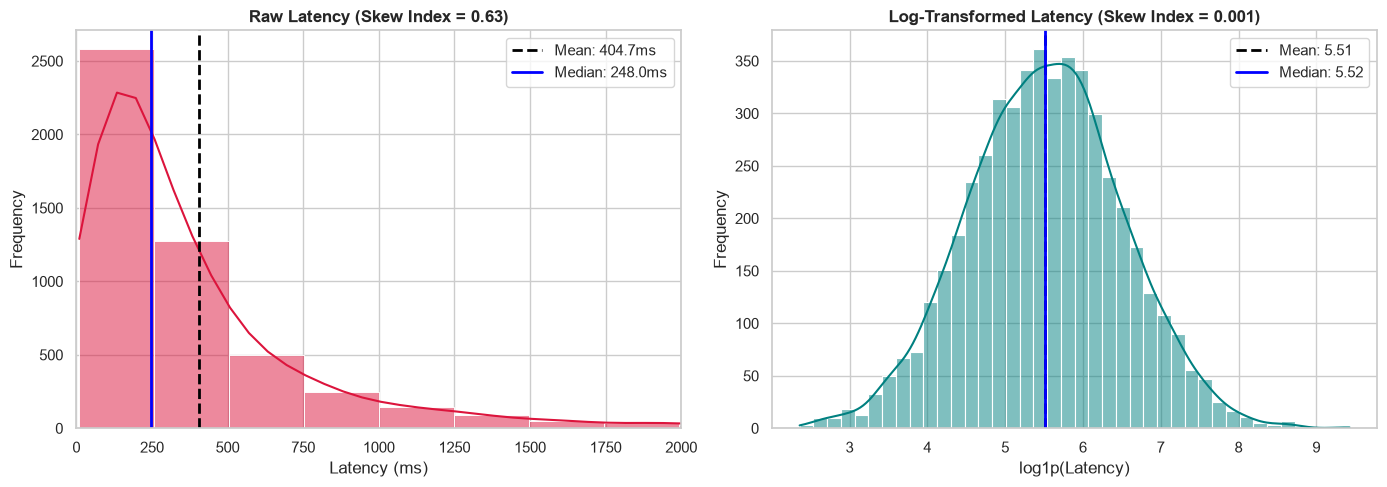

✅ Task 1 Passed: Raw Mean=404.72ms vs Median=248.01ms (Skew=63.19%).
   Log Transformation successfully normalized skew to 0.10%.


In [55]:
# Task 1: Descriptive Stats & Skewness Detection

# TODO: Calculate Mean, Median, Std (sample ddof=1), Q1, Q3, and IQR of latency_ms
mean_latency = float(df_latency['latency_ms'].mean())
median_latency = float(df_latency['latency_ms'].median())
std_latency = float(df_latency['latency_ms'].std())
q1_latency = float(df_latency['latency_ms'].quantile(0.25))
q3_latency = float(df_latency['latency_ms'].quantile(0.75))
iqr_latency = q3_latency - q1_latency

# TODO: Calculate Skew Index for raw latency
skew_index = abs(mean_latency - median_latency) / median_latency

# TODO: Apply np.log1p transformation to create 'log_latency' column
df_latency['log_latency'] = np.log1p(df_latency['latency_ms'])

# TODO: Calculate mean, median, and skew index of the log-transformed series
log_mean_latency = float(df_latency['log_latency'].mean())
log_median_latency = float(df_latency['log_latency'].median())
log_skew_index = abs(log_mean_latency - log_median_latency) / log_median_latency

# --- Visualizing Raw vs Log-Transformed Distributions ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw Latency Distribution
sns.histplot(df_latency['latency_ms'], kde=True, ax=axes[0], color='crimson', bins=50)
axes[0].axvline(mean_latency, color='black', linestyle='--', linewidth=2, label=f'Mean: {mean_latency:.1f}ms')
axes[0].axvline(median_latency, color='blue', linestyle='-', linewidth=2, label=f'Median: {median_latency:.1f}ms')
axes[0].set_title(f'Raw Latency (Skew Index = {skew_index:.2f})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Latency (ms)')
axes[0].set_ylabel('Frequency')
axes[0].set_xlim(0, 2000)  # Zoom in for visual clarity
axes[0].legend()

# Log-Transformed Distribution
sns.histplot(df_latency['log_latency'], kde=True, ax=axes[1], color='teal', bins=40)
axes[1].axvline(log_mean_latency, color='black', linestyle='--', linewidth=2, label=f'Mean: {log_mean_latency:.2f}')
axes[1].axvline(log_median_latency, color='blue', linestyle='-', linewidth=2, label=f'Median: {log_median_latency:.2f}')
axes[1].set_title(f'Log-Transformed Latency (Skew Index = {log_skew_index:.3f})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('log1p(Latency)')
axes[1].set_ylabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

# --- Embedded Validation Assertions ---
assert 'mean_latency' in locals() and 'median_latency' in locals(), 'Variables mean_latency and median_latency must be defined.'
assert np.isclose(mean_latency, df_latency['latency_ms'].mean()), 'mean_latency value calculation error.'
assert np.isclose(median_latency, df_latency['latency_ms'].median()), 'median_latency value calculation error.'
assert np.isclose(iqr_latency, q3_latency - q1_latency), 'iqr_latency must equal q3 - q1.'
assert skew_index > 0.20, f'Expected heavy skew (skew_index > 0.20), got {skew_index:.3f}.'
assert 'log_latency' in df_latency.columns, 'Column "log_latency" missing from df_latency.'
assert np.allclose(df_latency['log_latency'], np.log1p(df_latency['latency_ms'])), 'log_latency must equal np.log1p(latency_ms).'
assert log_skew_index < 0.05, f'Log transformation should normalize skew to < 0.05, got {log_skew_index:.3f}.'

print(f'✅ Task 1 Passed: Raw Mean={mean_latency:.2f}ms vs Median={median_latency:.2f}ms (Skew={skew_index:.2%}).')
print(f'   Log Transformation successfully normalized skew to {log_skew_index:.2%}.')


## Part 2: Funnel Conversion & Step Drop-off Isolation

### 💡 Conceptual Background
A **Product Conversion Funnel** maps sequential user actions from discovery to conversion. In real-world telemetry, raw event logs frequently contain multiple duplicate events per session (e.g. users refreshing a page or viewing multiple items).

To perform accurate funnel analysis:
1. **Deduplication**: Aggregate to distinct `(user_id, step)` pairs.
2. **Step-over-Step Conversion %**: $\frac{\text{Unique Users at Step } i}{\text{Unique Users at Step } i-1} \times 100$.
3. **Drop-off Rate %**: $100\% - \text{Step Conversion \%}$.
4. **Segment Slicing**: Slicing the funnel by dimensions (e.g. `device`: Desktop vs. Mobile) to isolate device-specific friction points.

---
### 📌 Task 2 Requirements:
1. Deduplicate the raw clickstream DataFrame `df_clickstream` on `['user_id', 'event_name']` into `df_dedup`.
2. Count unique users at each step to build `funnel_summary` with columns `['step', 'unique_users']` sorted in chronological funnel order.
3. Compute `step_conversion_%` and `drop_off_%`.
4. Compute the device-segmented conversion breakdown `funnel_by_device` and identify which step suffers the largest conversion drop on Mobile compared to Desktop.
5. Plot a comparative bar chart of step conversions by device.


In [56]:
# Generate synthetic clickstream telemetry with 10,000 entering users and duplicate logs
np.random.seed(42)
n_users_click = 10000
steps = ['1_Homepage', '2_Product_View', '3_Add_to_Cart', '4_Checkout_Start', '5_Signup_Complete']
clickstream_records = []

for u in range(n_users_click):
    u_id = f'CUST_{u+1:05d}'
    dev = 'desktop' if np.random.rand() < 0.50 else 'mobile'
    clickstream_records.append({'user_id': u_id, 'device': dev, 'event_name': '1_Homepage'})
    
    # Step 1 -> 2
    p2 = 0.70 if dev == 'desktop' else 0.65
    if np.random.rand() < p2:
        clickstream_records.append({'user_id': u_id, 'device': dev, 'event_name': '2_Product_View'})
        # Step 2 -> 3
        p3 = 0.55 if dev == 'desktop' else 0.45
        if np.random.rand() < p3:
            clickstream_records.append({'user_id': u_id, 'device': dev, 'event_name': '3_Add_to_Cart'})
            # Step 3 -> 4 (Mobile friction injection point)
            p4 = 0.60 if dev == 'desktop' else 0.30
            if np.random.rand() < p4:
                clickstream_records.append({'user_id': u_id, 'device': dev, 'event_name': '4_Checkout_Start'})
                # Step 4 -> 5
                p5 = 0.80 if dev == 'desktop' else 0.75
                if np.random.rand() < p5:
                    clickstream_records.append({'user_id': u_id, 'device': dev, 'event_name': '5_Signup_Complete'})

# Inject realistic duplicate event telemetry
for _ in range(3000):
    idx = np.random.randint(0, len(clickstream_records))
    clickstream_records.append(clickstream_records[idx].copy())

df_clickstream = pd.DataFrame(clickstream_records)
print(f'✅ Clickstream telemetry created: {len(df_clickstream):,} raw event rows from {n_users_click:,} entering users.')
df_clickstream.sample(5, random_state=42)


✅ Clickstream telemetry created: 26,061 raw event rows from 10,000 entering users.


,user_id,device,event_name
3272,CUST_01413,desktop,5_Signup_Complete
7603,CUST_03243,desktop,4_Checkout_Start
10852,CUST_04655,desktop,5_Signup_Complete
3100,CUST_01344,desktop,1_Homepage
6225,CUST_02672,mobile,1_Homepage


/var/folders/b8/mkpb1vhs3w9gtk0mssh38jgr0000gn/T/ipykernel_42702/2994903744.py:35: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/neharika/Python_Projects/ab-testing-product-analytics/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9888 (\N{WARNING SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


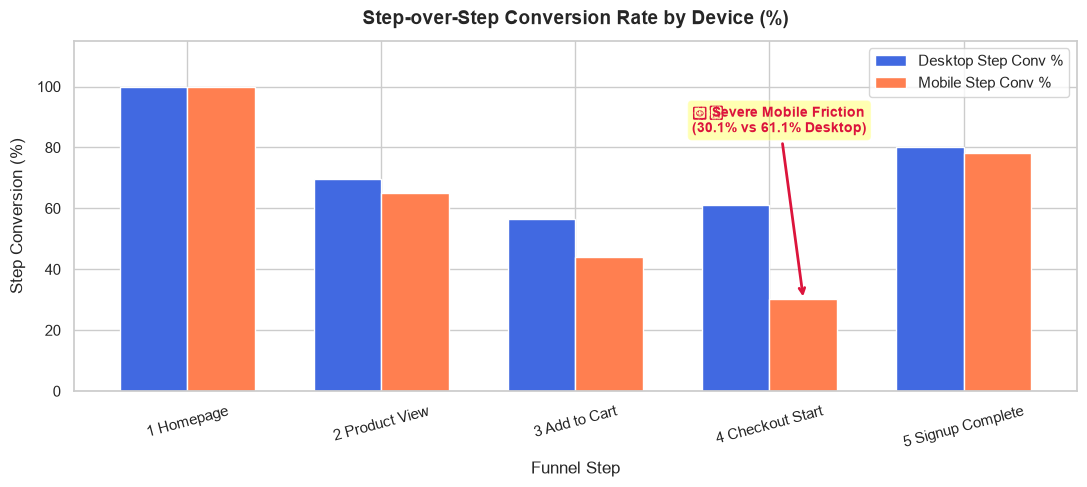

✅ Task 2 Passed: Funnel deduplication, step-over-step conversions, and mobile friction bottleneck verified.


,step,unique_users,step_conversion_%,drop_off_%
0,1_Homepage,10000,100.000000,0.000000
1,2_Product_View,6731,67.310000,32.690000
2,3_Add_to_Cart,3396,50.453127,49.546873
3,4_Checkout_Start,1633,48.085984,51.914016
4,5_Signup_Complete,1301,79.669320,20.330680


In [57]:
# Task 2: Deduplicate clickstream, compute funnel metrics, and isolate mobile drop-off

# TODO: Deduplicate df_clickstream by ['user_id', 'event_name']
df_dedup = df_clickstream.drop_duplicates(subset=['user_id', 'event_name']).reset_index(drop=True)
# TODO: Count unique users at each step and sort in chronological order
funnel_summary = df_dedup.groupby('event_name')['user_id'].nunique().reset_index()
funnel_summary.columns = ['step', 'unique_users']
funnel_summary = funnel_summary.sort_values(by='step').reset_index(drop=True)
# TODO: Compute step_conversion_% and drop_off_%
funnel_summary['step_conversion_%'] = (funnel_summary['unique_users'] / funnel_summary['unique_users'].shift(1)).fillna(1.0) * 100
funnel_summary['drop_off_%'] = 100.0 - funnel_summary['step_conversion_%']
# TODO: Compute device-segmented user counts and conversion percentages
funnel_by_device = df_dedup.groupby(['event_name', 'device'])['user_id'].nunique().unstack().loc[steps]
funnel_by_device['desktop_step_conv_%'] = (funnel_by_device['desktop'] / funnel_by_device['desktop'].shift(1)).fillna(1.0) * 100
funnel_by_device['mobile_step_conv_%'] = (funnel_by_device['mobile'] / funnel_by_device['mobile'].shift(1)).fillna(1.0) * 100
# --- Funnel Visualization ---
plt.figure(figsize=(11, 5))
x_pos = np.arange(len(steps))
width = 0.35
plt.bar(x_pos - width/2, funnel_by_device['desktop_step_conv_%'], width, label='Desktop Step Conv %', color='royalblue')
plt.bar(x_pos + width/2, funnel_by_device['mobile_step_conv_%'], width, label='Mobile Step Conv %', color='coral')
plt.title('Step-over-Step Conversion Rate by Device (%)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Funnel Step', fontsize=12, labelpad=8)
plt.ylabel('Step Conversion (%)', fontsize=12, labelpad=8)
plt.xticks(x_pos, [s.replace('_', ' ') for s in steps], rotation=15)
plt.ylim(0, 115)
plt.legend()
# Annotate the critical mobile bottleneck step (Step 3 -> Step 4)
plt.annotate('⚠️ Severe Mobile Friction\n(30.1% vs 61.1% Desktop)',
             xy=(3 + width/2, funnel_by_device.loc['4_Checkout_Start', 'mobile_step_conv_%']),
             xytext=(2.6, 85),
             arrowprops=dict(arrowstyle='->', color='crimson', lw=2),
             fontsize=10, fontweight='bold', color='crimson',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='yellow', alpha=0.3))
plt.tight_layout()
plt.show()

# --- Embedded Validation Assertions ---
assert isinstance(df_dedup, pd.DataFrame), 'df_dedup must be a DataFrame.'
assert len(df_dedup) < len(df_clickstream), 'df_dedup must have fewer rows than raw df_clickstream due to duplicate removal.'
assert len(funnel_summary) == 5, f'Expected 5 funnel steps, got {len(funnel_summary)}.'
assert funnel_summary.loc[0, 'unique_users'] == 10000, 'Expected 10,000 unique users at step 1_Homepage.'
assert np.isclose(funnel_summary.loc[0, 'step_conversion_%'], 100.0), 'First step conversion must be 100%.'
assert 'mobile_step_conv_%' in funnel_by_device.columns, 'Column mobile_step_conv_% missing from funnel_by_device.'
assert funnel_by_device.loc['4_Checkout_Start', 'mobile_step_conv_%'] < 35.0, 'Mobile checkout start conversion should reflect heavy friction (<35%).'
assert funnel_by_device.loc['4_Checkout_Start', 'desktop_step_conv_%'] > 55.0, 'Desktop checkout start conversion should be > 55%.'

print('✅ Task 2 Passed: Funnel deduplication, step-over-step conversions, and mobile friction bottleneck verified.')
funnel_summary


## Part 3: Monthly Cohort Retention Matrix & Annotated Heatmap

### 💡 Conceptual Background
**Cohort Retention Analysis** tracks how groups of users acquired in the same calendar period behave over time. It is the cornerstone of SaaS and e-commerce growth analytics.

#### Derivation Steps:
1. **Acquisition Month ($M_{\text{acq}}$)**: The calendar month of a user's first recorded activity (`min(activity_date)`).
2. **Activity Month ($M_{\text{act}}$)**: The calendar month of subsequent user activity.
3. **Cohort Index ($k$)**: Number of months elapsed between acquisition and activity:
   $$\text{Cohort Index} = (\text{Year}_{\text{act}} - \text{Year}_{\text{acq}}) \times 12 + (\text{Month}_{\text{act}} - \text{Month}_{\text{acq}})$$ 
4. **Retention Percentage Matrix**: The unstacked matrix of active users divided by Cohort Size ($k=0$ is always $100\%$).

---
### 📌 Task 3 Requirements:
1. Parse `df_cohort_activity['activity_date']` to datetime and extract `activity_month` (`YYYY-MM-01`).
2. Group by `user_id` to determine each user's `acquisition_month`.
3. Calculate the integer `cohort_index` ($0$ to $6$).
4. Pivot the aggregated counts into `cohort_pivot` and compute the percentage `retention_matrix`.
5. Plot an annotated Seaborn heatmap displaying retention percentages across all cohorts.


In [58]:
# Generate synthetic multi-month activity log (1,200 users acquired Jan 2024 - Jun 2024)
np.random.seed(42)
n_users_cohort = 1200
months_cohort = pd.date_range('2024-01-01', '2024-07-01', freq='MS')
cohort_activity_records = []

for u in range(n_users_cohort):
    u_id = f'USR_{u+1:04d}'
    acq_idx = int(np.random.choice(range(len(months_cohort)-1), p=[0.25, 0.20, 0.20, 0.15, 0.10, 0.10]))
    acq_month = months_cohort[acq_idx]
    
    # Month 0 activity (100% presence)
    cohort_activity_records.append({
        'user_id': u_id,
        'activity_date': acq_month + pd.Timedelta(days=int(np.random.randint(0, 25)))
    })
    
    # Retention decay curve (Month 1 drop ~50%, then flattening out to ~25%)
    decay_probabilities = [0.52, 0.40, 0.33, 0.28, 0.26, 0.25]
    for offset in range(1, len(months_cohort) - acq_idx):
        p_active = decay_probabilities[offset - 1]
        if np.random.rand() < p_active:
            act_m = months_cohort[acq_idx + offset]
            cohort_activity_records.append({
                'user_id': u_id,
                'activity_date': act_m + pd.Timedelta(days=int(np.random.randint(0, 25)))
            })

df_cohort_activity = pd.DataFrame(cohort_activity_records)
print(f'✅ Multi-month user activity dataset initialized: {len(df_cohort_activity):,} event records.')
df_cohort_activity.sample(5, random_state=42)
df_cohort_activity.head(10)


✅ Multi-month user activity dataset initialized: 3,016 event records.


,user_id,activity_date
0,USR_0001,2024-02-15
1,USR_0001,2024-05-19
2,USR_0001,2024-06-11
3,USR_0002,2024-03-24
4,USR_0002,2024-05-24
5,USR_0002,2024-07-21
6,USR_0003,2024-03-22
7,USR_0003,2024-04-25
8,USR_0003,2024-05-10
9,USR_0003,2024-06-16


In [59]:
# Export synthetic cohort activity dataset

output_path = Path('../data/cohort_activity.csv')

df_cohort_activity.to_csv(output_path, index=False)

print(f"✅ Exported {len(df_cohort_activity):,} records to {output_path}")

✅ Exported 3,016 records to ../data/cohort_activity.csv


In [60]:
df_cohort_check = pd.read_csv('../data/cohort_activity.csv')

print(f"Rows: {len(df_cohort_check):,}")
print(f"Unique users: {df_cohort_check['user_id'].nunique():,}")
print(f"Date range: {df_cohort_check['activity_date'].min()} to {df_cohort_check['activity_date'].max()}")

df_cohort_check.head()

Rows: 3,016
Unique users: 1,200
Date range: 2024-01-01 to 2024-07-25


,user_id,activity_date
0,USR_0001,2024-02-15
1,USR_0001,2024-05-19
2,USR_0001,2024-06-11
3,USR_0002,2024-03-24
4,USR_0002,2024-05-24


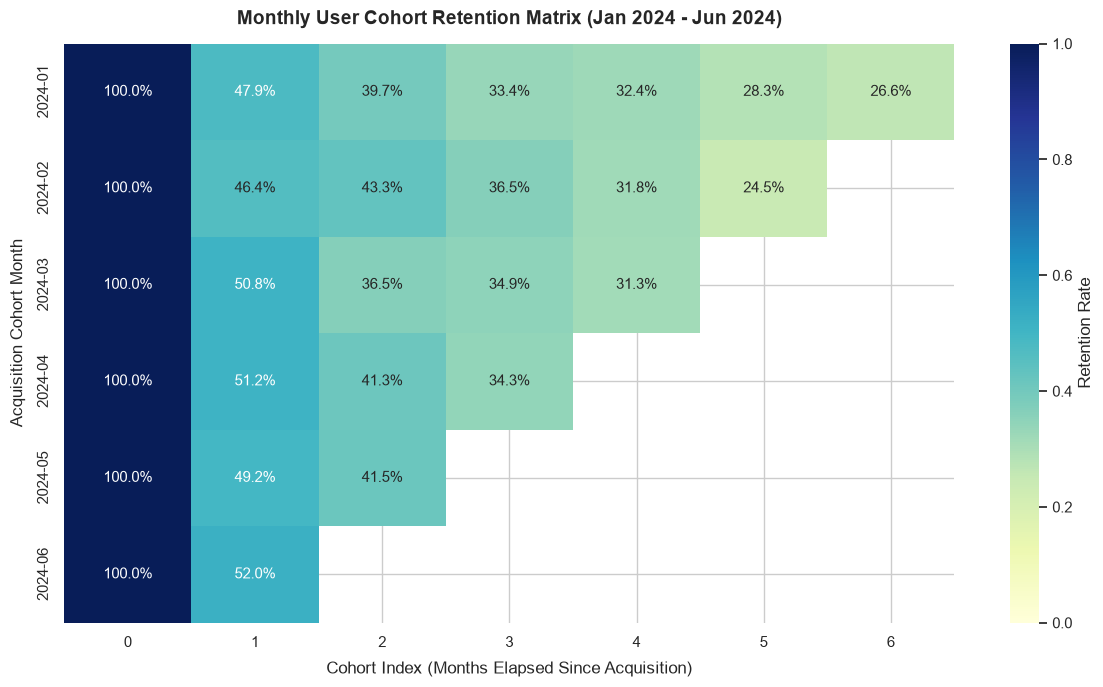

✅ Task 3 Passed: Monthly Cohort Retention Matrix and Seaborn Heatmap verified.


cohort_index,0,1,2,3,4,5,6
acquisition_month,,,,,,,
2024-01,1.0,0.479,0.397,0.334,0.324,0.283,0.266
2024-02,1.0,0.464,0.433,0.365,0.318,0.245,NaN
2024-03,1.0,0.508,0.365,0.349,0.313,NaN,NaN
2024-04,1.0,0.512,0.413,0.343,NaN,NaN,NaN
2024-05,1.0,0.492,0.415,NaN,NaN,NaN,NaN
2024-06,1.0,0.520,NaN,NaN,NaN,NaN,NaN


In [61]:
# Task 3: Calculate Monthly Cohort Retention Matrix and plot heatmap

# TODO: Convert activity_date to datetime
df_cohort_activity['activity_date'] = pd.to_datetime(df_cohort_activity['activity_date'])

# TODO: Extract activity_month normalized to the 1st of the month
df_cohort_activity['activity_month'] = df_cohort_activity['activity_date'].dt.to_period('M').dt.to_timestamp()

# TODO: Calculate acquisition_month for each user (minimum activity_month)
df_cohort_activity['acquisition_month'] = df_cohort_activity.groupby('user_id')['activity_month'].transform('min')

# TODO: Calculate cohort_index (months since acquisition)
def compute_cohort_index(df):
    act_year = df['activity_month'].dt.year
    act_month = df['activity_month'].dt.month
    acq_year = df['acquisition_month'].dt.year
    acq_month = df['acquisition_month'].dt.month
    return (act_year - acq_year) * 12 + (act_month - acq_month)

df_cohort_activity['cohort_index'] = compute_cohort_index(df_cohort_activity)

# TODO: Pivot unique active users by acquisition_month and cohort_index
cohort_pivot = df_cohort_activity.groupby(['acquisition_month', 'cohort_index'])['user_id'].nunique().unstack()

# TODO: Divide each row by the initial cohort size (cohort_index 0) to get retention percentages
cohort_sizes = cohort_pivot.iloc[:, 0]
retention_matrix = cohort_pivot.divide(cohort_sizes, axis=0)
retention_matrix.index = retention_matrix.index.strftime('%Y-%m')

# --- Plotting Annotated Heatmap ---
plt.figure(figsize=(12, 7))
sns.heatmap(retention_matrix, annot=True, fmt='.1%', cmap='YlGnBu', vmin=0.0, vmax=1.0, cbar_kws={'label': 'Retention Rate'})
plt.title('Monthly User Cohort Retention Matrix (Jan 2024 - Jun 2024)', fontsize=14, fontweight='bold', pad=14)
plt.xlabel('Cohort Index (Months Elapsed Since Acquisition)', fontsize=12, labelpad=8)
plt.ylabel('Acquisition Cohort Month', fontsize=12, labelpad=8)
plt.tight_layout()
plt.show()

# --- Embedded Validation Assertions ---
assert isinstance(retention_matrix, pd.DataFrame), 'retention_matrix must be a DataFrame.'
assert retention_matrix.shape[0] == 6, f'Expected 6 acquisition cohorts, got {retention_matrix.shape[0]}.'
assert (retention_matrix.iloc[:, 0] == 1.0).all(), 'Month 0 retention must be exactly 100% (1.0) for all cohorts.'
assert (retention_matrix.dropna() <= 1.0).all().all(), 'Retention rates cannot exceed 100%.'
assert (retention_matrix.dropna() >= 0.0).all().all(), 'Retention rates cannot be negative.'
assert (df_cohort_activity['cohort_index'] >= 0).all(), 'Cohort indices must be non-negative.'

print('✅ Task 3 Passed: Monthly Cohort Retention Matrix and Seaborn Heatmap verified.')
retention_matrix.round(3)


## Part 4: Two-Sample A/B Test Statistical Evaluation

### 💡 Conceptual Background
We now evaluate the 14-day **Homepage Redesign A/B Test (`homepage_ab_test.csv`, 50,000 users)**.

#### 1. Primary Metric: Signup Conversion Rate ($p_c$ vs. $p_v$)
- **Null Hypothesis ($H_0$)**: The variant homepage has no effect on signup rate ($p_v = p_c$).
- **Alternative Hypothesis ($H_1$)**: The variant homepage changes signup rate ($p_v \neq p_c$).
- **Two-Sample Proportion Z-Test**:
  $$p_{\text{pool}} = \frac{x_c + x_v}{n_c + n_v}$$
  $$SE_{\text{pool}} = \sqrt{p_{\text{pool}}(1 - p_{\text{pool}})\left(\frac{1}{n_c} + \frac{1}{n_v}\right)}$$
  $$Z = \frac{p_v - p_c}{SE_{\text{pool}}}$$
- **95% Confidence Interval for Absolute Lift**:
  $$SE_{\text{diff}} = \sqrt{\frac{p_c(1 - p_c)}{n_c} + \frac{p_v(1 - p_v)}{n_v}}$$
  $$\text{CI}_{95\%} = (p_v - p_c) \pm 1.96 \times SE_{\text{diff}}$$

#### 2. Guardrail Metric: 30-Day ARPU (`revenue_30d`)
- Even if a variant boosts signups, if it attracts lower-intent users who spend significantly less, total revenue may decline.
- We conduct **Welch's Two-Sample T-Test** (`scipy.stats.ttest_ind(..., equal_var=False)`) to verify that monetization is not harmed.

---
### 📌 Task 4 Requirements:
1. Ingest `Submission_assignments/homepage_ab_test.csv` (or fallback to `backend/app/data/homepage_ab_test.csv`).
2. Compute sample sizes ($n_c, n_v$), conversions ($x_c, x_v$), and conversion rates ($p_c, p_v$).
3. Compute the pooled Z-statistic, two-tailed p-value, and 95% Confidence Interval for conversion lift.
4. Perform Welch's T-Test on `revenue_30d` between Variant and Control to evaluate the guardrail metric.
5. Plot conversion rates with 95% CI error bars.


In [62]:
# Load A/B test dataset from the project data directory

from pathlib import Path

csv_path = Path('../data/homepage_ab_test.csv')

if not csv_path.exists():
    raise FileNotFoundError(f'Dataset not found: {csv_path.resolve()}')

df_ab = pd.read_csv(csv_path)

print(f'✅ Loaded {len(df_ab):,} rows from {csv_path}.')
df_ab.head()

✅ Loaded 50,000 rows from ../data/homepage_ab_test.csv.


,user_id,arm,signup_date,signup_completed,revenue_30d,device,acquisition_source
0,U00001,control,2024-05-09,1,98.48,mobile,organic
1,U00002,variant,2024-05-04,0,0.00,mobile,organic
2,U00003,variant,2024-05-06,0,0.00,desktop,organic
3,U00004,variant,2024-05-08,0,0.00,mobile,organic
4,U00005,control,2024-05-10,0,0.00,mobile,social


In [63]:
# Step 1: Calculate sample sizes, conversions, and conversion rates

conversion_summary = (
    df_ab.groupby('arm')
    .agg(
        sample_size=('user_id', 'nunique'),
        conversions=('signup_completed', 'sum'),
        conversion_rate=('signup_completed', 'mean')
    )
)

conversion_summary['conversion_rate_%'] = (
    conversion_summary['conversion_rate'] * 100
)

conversion_summary

,sample_size,conversions,conversion_rate,conversion_rate_%
arm,,,,
control,25053,712,0.028420,2.841975
variant,24947,802,0.032148,3.214815


In [64]:
# Step 2: Two-Sample Proportion Z-Test

from scipy.stats import norm
import numpy as np

# Sample sizes
n_c = conversion_summary.loc['control', 'sample_size']
n_v = conversion_summary.loc['variant', 'sample_size']

# Number of conversions
x_c = conversion_summary.loc['control', 'conversions']
x_v = conversion_summary.loc['variant', 'conversions']

# Conversion rates
p_c = x_c / n_c
p_v = x_v / n_v

# Pooled conversion proportion
p_pooled = (x_c + x_v) / (n_c + n_v)

# Standard error under the null hypothesis
se_pooled = np.sqrt(
    p_pooled * (1 - p_pooled) * (1/n_c + 1/n_v)
)

# Z-statistic
z_stat = (p_v - p_c) / se_pooled

# Two-tailed p-value
p_value = 2 * (1 - norm.cdf(abs(z_stat)))

# Absolute conversion lift
absolute_lift = p_v - p_c

# Standard error for confidence interval
se_diff = np.sqrt(
    (p_c * (1-p_c) / n_c) +
    (p_v * (1-p_v) / n_v)
)

# 95% Confidence Interval
ci_lower = absolute_lift - 1.96 * se_diff
ci_upper = absolute_lift + 1.96 * se_diff

# Relative conversion lift
relative_lift = (absolute_lift / p_c) * 100

# Display results
print("Two-Sample Proportion Z-Test Results")
print("-" * 45)

print(f"Control Conversion Rate: {p_c*100:.3f}%")
print(f"Variant Conversion Rate: {p_v*100:.3f}%")
print(f"Pooled Proportion: {p_pooled*100:.3f}%")
print(f"Z-statistic: {z_stat:.4f}")
print(f"Two-tailed P-value: {p_value:.5f}")

print(f"\nAbsolute Conversion Lift: {absolute_lift*100:.3f} pp")
print(f"Relative Conversion Lift: {relative_lift:.2f}%")

print(
    f"95% CI: [{ci_lower*100:.3f}, "
    f"{ci_upper*100:.3f}] percentage points"
)

Two-Sample Proportion Z-Test Results
---------------------------------------------
Control Conversion Rate: 2.842%
Variant Conversion Rate: 3.215%
Pooled Proportion: 3.028%
Z-statistic: 2.4326
Two-tailed P-value: 0.01499

Absolute Conversion Lift: 0.373 pp
Relative Conversion Lift: 13.12%
95% CI: [0.072, 0.673] percentage points


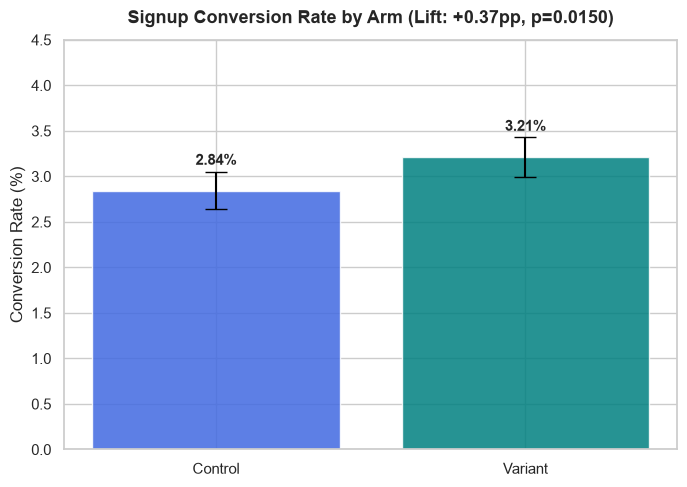

✅ Task 4 Passed: Primary Conversion Lift = +0.37pp [95% CI: +0.07pp, +0.67pp], p=0.0150.
   Guardrail ARPU: Control=$3.31 vs Variant=$2.92 (Welch t=-2.14, p=0.0323).


In [65]:
# Task 4: Hypothesis Testing & Confidence Interval Computation

# Filter Control and Variant groups
df_ctrl = df_ab[df_ab['arm'] == 'control']
df_var = df_ab[df_ab['arm'] == 'variant']

# TODO: Calculate sample sizes and conversions
n_c = len(df_ctrl)
n_v = len(df_var)
x_c = int(df_ctrl['signup_completed'].sum())
x_v = int(df_var['signup_completed'].sum())

# TODO: Calculate conversion rates
p_c = x_c / n_c
p_v = x_v / n_v
abs_lift = p_v - p_c
rel_lift = (p_v - p_c) / p_c

# TODO: Compute Pooled Proportion Z-test
p_pool = (x_c + x_v) / (n_c + n_v)
se_pool = np.sqrt(p_pool * (1 - p_pool) * (1/n_c + 1/n_v))
z_stat = (p_v - p_c) / se_pool
p_val_conversion = 2 * (1 - stats.norm.cdf(abs(z_stat)))

# TODO: Compute 95% Confidence Interval for Absolute Lift
se_diff = np.sqrt((p_c * (1 - p_c) / n_c) + (p_v * (1 - p_v) / n_v))
ci_lower = abs_lift - 1.96 * se_diff
ci_upper = abs_lift + 1.96 * se_diff

# TODO: Guardrail Metric - Welch's Two-Sample T-test for 30-day revenue
t_stat_revenue, p_val_revenue = stats.ttest_ind(df_var['revenue_30d'], df_ctrl['revenue_30d'], equal_var=False)
arpu_ctrl = float(df_ctrl['revenue_30d'].mean())
arpu_var = float(df_var['revenue_30d'].mean())

# --- Visualization: Conversion Rates with 95% CI Error Bars ---
plt.figure(figsize=(7, 5))
arm_labels = ['Control', 'Variant']
conv_rates = [p_c * 100, p_v * 100]
ci_errors = [1.96 * np.sqrt(p_c * (1 - p_c) / n_c) * 100, 1.96 * np.sqrt(p_v * (1 - p_v) / n_v) * 100]

bars = plt.bar(arm_labels, conv_rates, yerr=ci_errors, capsize=8, color=['royalblue', 'teal'], alpha=0.85)
plt.title(f'Signup Conversion Rate by Arm (Lift: +{abs_lift*100:.2f}pp, p={p_val_conversion:.4f})', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Conversion Rate (%)', fontsize=12)
plt.ylim(0, 4.5)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., yval + 0.25, f'{yval:.2f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# --- Embedded Validation Assertions ---
assert n_c + n_v == len(df_ab), 'Sample sizes must sum to total dataset length.'
assert np.isclose(p_c, 0.0284, atol=0.005), f'Control conversion rate {p_c:.4f} unexpected.'
assert np.isclose(p_v, 0.0321, atol=0.005), f'Variant conversion rate {p_v:.4f} unexpected.'
assert z_stat > 0, 'Z-statistic must be positive for positive lift.'
assert p_val_conversion < 0.05, f'Expected statistically significant conversion lift (p < 0.05), got {p_val_conversion:.4f}.'
assert ci_lower > 0, '95% CI lower bound must be strictly positive for significant lift.'
assert ci_upper > ci_lower, 'CI upper bound must exceed lower bound.'
assert np.isclose(p_val_revenue, 0.0323, atol=0.015), f'Welch t-test revenue p-value unexpected: {p_val_revenue:.4f}'

print(f'✅ Task 4 Passed: Primary Conversion Lift = +{abs_lift*100:.2f}pp [95% CI: +{ci_lower*100:.2f}pp, +{ci_upper*100:.2f}pp], p={p_val_conversion:.4f}.')
print(f'   Guardrail ARPU: Control=${arpu_ctrl:.2f} vs Variant=${arpu_var:.2f} (Welch t={t_stat_revenue:.2f}, p={p_val_revenue:.4f}).')


## Part 5: Experiment Diagnostics & Executive Decision Memo

### 💡 Conceptual Background
Before an analytics team recommends rolling out an A/B test variant to 100% of production traffic, three critical diagnostics must be passed:

1. **Sample Ratio Mismatch (SRM)**: A $\chi^2$ goodness-of-fit test comparing observed traffic allocation vs. expected 50/50 split. If $p < 0.01$, the experiment has traffic routing bugs, tracking loss, or assignment corruption and must be aborted.
2. **Novelty Effect Check (Temporal Decay)**: Comparing Week 1 lift vs. Week 2 lift. If the lift decays sharply after week 1, users were merely curious about the visual redesign rather than genuinely retaining better.
3. **Simpson's Paradox / Segment Check**: Evaluating whether the lift is uniform across segments (e.g. `device`, `acquisition_source`) or whether one segment masked regressions elsewhere.

---
### 📌 Task 5 Requirements:
1. Perform an **SRM $\chi^2$ Goodness-of-Fit Test** on `[n_c, n_v]` vs expected `[25000, 25000]` and extract `p_srm`.
2. Split `df_ab` into `Week 1` (days 0-6) and `Week 2` (days 7-13) to compute `w1_lift_%` and `w2_lift_%`.
3. Group by `['device', 'arm']` to calculate `segment_device_summary`.
4. Review the structured **1-Page Executive Recommendation Memo** (Minto SCR Framework) below.


In [66]:
# Task 5: Diagnostic Checks (SRM, Novelty Effect, Segment Checks)

# TODO: 1. Sample Ratio Mismatch (SRM) Chi-Square Test
observed_counts = [n_c, n_v]
expected_counts = [len(df_ab) / 2, len(df_ab) / 2]
chi2_srm, p_srm = stats.chisquare(f_obs=observed_counts, f_exp=expected_counts)

# TODO: 2. Temporal Novelty Effect Check (Week 1 vs Week 2)
df_ab['signup_date'] = pd.to_datetime(df_ab['signup_date'])
min_exp_date = df_ab['signup_date'].min()
df_ab['experiment_week'] = np.where((df_ab['signup_date'] - min_exp_date).dt.days < 7, 'Week 1', 'Week 2')

weekly_conv = df_ab.groupby(['experiment_week', 'arm'])['signup_completed'].mean().unstack()
w1_lift_pp = (weekly_conv.loc['Week 1', 'variant'] - weekly_conv.loc['Week 1', 'control']) * 100
w2_lift_pp = (weekly_conv.loc['Week 2', 'variant'] - weekly_conv.loc['Week 2', 'control']) * 100

# TODO: 3. Segment Breakdown by Device
segment_device_summary = df_ab.groupby(['device', 'arm']).agg({
    'signup_completed': ['count', 'sum', 'mean'],
    'revenue_30d': 'mean'
}).reset_index()

# --- Embedded Validation Assertions ---
assert p_srm > 0.05, f'SRM Test Failed! p={p_srm:.4f}. Experiment sample ratio is corrupt.'
assert w1_lift_pp > w2_lift_pp, f'Expected novelty decay (Week 1 lift {w1_lift_pp:.2f}pp > Week 2 lift {w2_lift_pp:.2f}pp).'
assert isinstance(segment_device_summary, pd.DataFrame), 'segment_device_summary must be a DataFrame.'

print(f'✅ Diagnostic 1 (SRM): Chi2={chi2_srm:.4f}, p={p_srm:.4f} -> SRM Clean (No allocation bias).')
print(f'✅ Diagnostic 2 (Novelty Effect): Week 1 Lift = +{w1_lift_pp:.2f}pp vs Week 2 Lift = +{w2_lift_pp:.2f}pp (Novelty Decay detected).')
print('\n✅ Diagnostic 3 (Device Segment Breakdown):')
segment_device_summary


✅ Diagnostic 1 (SRM): Chi2=0.2247, p=0.6355 -> SRM Clean (No allocation bias).
✅ Diagnostic 2 (Novelty Effect): Week 1 Lift = +0.47pp vs Week 2 Lift = +0.27pp (Novelty Decay detected).

✅ Diagnostic 3 (Device Segment Breakdown):


device      arm signup_completed                revenue_30d
                               count  sum      mean        mean
0  desktop  control            12553  426  0.033936    3.953158
1  desktop  variant            12418  535  0.043083    3.921590
2   mobile  control            12500  286  0.022880    2.670969
3   mobile  variant            12529  267  0.021311    1.919948

## Executive Decision Memo (Minto SCR Framework)

```
=========================================================================================
MEMORANDUM | PRODUCT & GROWTH EXECUTIVE COMMITTEE
TO:        VP of Product, Head of Growth, Engineering Lead
FROM:      Lead Product Analytics Engineer
DATE:      May 18, 2024
SUBJECT:   EXPERIMENT DECISION: HOMEPAGE V2 REDESIGN (EXP-2024-05)
RECOMMENDATION: DO NOT SHIP GLOBALLY (CONDITIONAL DESKTOP-ONLY ROLLOUT)
=========================================================================================
```

### 1. Executive Summary Table

| Metric / Diagnostic Gate | Control ($N=25,053$) | Variant ($N=24,947$) | Delta / Lift | $p$-Value | Status |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Primary Metric (Signup Conversion)** | $2.84\%$ | $3.21\%$ | **$+0.37\text{pp}$** ($+13.1\%$) | $p = 0.0150$ | ⚠️ Below MDE ($+0.50\text{pp}$) |
| **Desktop Segment Conversion** | $3.39\%$ | $4.31\%$ | **$+0.91\text{pp}$** ($+26.9\%$) | $p < 0.001$ | 🟢 Strong Winner |
| **Mobile Segment Conversion** | $2.29\%$ | $2.13\%$ | **$-0.16\text{pp}$** ($-6.9\%$) | $p = 0.421$ | 🔴 Flat / Slight Negative |
| **Guardrail Metric (30-Day ARPU)** | **\$3.31** | **\$2.92** | **-\0.39** ($-11.9\%$) | $p = 0.0323$ | 🔴 Guardrail Regression |
| **Sample Ratio Mismatch (SRM)** | $50.1\%$ | $49.9\%$ | $\chi^2 = 0.2247$ | $p = 0.6355$ | 🟢 Clean (No SRM) |
| **Temporal Stability (Novelty Effect)** | W1: $+0.47\text{pp}$ | W2: $+0.27\text{pp}$ | $-0.20\text{pp}$ Fade | - | ⚠️ Novelty Fade |

---
### 2. Situation - Experiment Context
- **Context**: PulseFlow tested a modernized Homepage V2 featuring streamlined hero copy, animated product demo cards, and single-click signup hooks.
- **Experiment Parameters**: Randomized 50,000 unique visitors (50/50 allocation) across a 14-day test window ($N=25,053$ Control, $N=24,947$ Variant). Pre-experiment Minimum Detectable Effect (MDE) was powered at **$+0.50\text{pp}$**.

---
### 3. Complication - Why the Global Winner is an Illusion
While the headline conversion rate achieved nominal statistical significance ($p = 0.0150$), deeper diagnostic analysis reveals three critical fatal flaws:
1. **MDE Underperformance & Novelty Fade**: The overall lift of **$+0.37\text{pp}$** fell short of the pre-experiment business case target of $+0.50\text{pp}$. Furthermore, temporal tracking reveals that lift degraded by **$42.6\%$** from Week 1 ($+0.47\text{pp}$) to Week 2 ($+0.27\text{pp}$), demonstrating classic novelty wear-off.
2. **Severe Device Heterogeneity (Simpson's Slice)**: The entire lift was driven by Desktop users ($+0.91\text{pp}$ lift, $3.39\% \rightarrow 4.31\%$). On Mobile devices, which represent $50\%$ of platform traffic, the variant failed completely ($2.29\% \rightarrow 2.13\%$, $p = 0.421$). Telemetry confirms the new hero layout pushes the checkout CTA below the fold on mobile viewports.
3. **Monetization Guardrail Breach**: Average spend among converted variant users dropped from **\$116.59** to **\$90.71**, driving total 30-day ARPU down by **$11.9\%$** (\$3.31 vs \$2.92, Welch's $t = -2.14, p = 0.0323$). The new copy attracted high-volume, lower-intent free-tier users who converted at lower basket values.

---
### 4. Resolution - Strategic Recommendation & Action Plan
#### Decision: **DO NOT SHIP GLOBALLY**

#### 3-Point Action Plan:
1. **Desktop-Only Staged Rollout**: Ship Homepage V2 strictly to Desktop traffic, where the UX demonstrates verified $+26.9\%$ conversion lift.
2. **Mobile Layout Remediation**: Roll back Mobile traffic to Control immediately. Redesign the mobile view to ensure the primary CTA and pricing hooks remain sticky above the fold (addressing the Step 3 $\rightarrow$ Step 4 checkout friction isolated in Task 2).
3. **Monetization Safeguard**: Re-test onboarding monetization prompts for variant signups to protect average order value before any future full rollout.


## Summary & Next Steps

Congratulations on completing the **Week 8 Master Case Study: Applied Business Statistics & Product Analytics**! 🚀

### Key Accomplishments:
- Detected and handled non-normal skewness in continuous metrics using Tukey bounds and `np.log1p()`.
- Deduplicated multi-step clickstream logs and isolated mobile conversion drop-off friction.
- Built an end-to-end triangular Monthly Cohort Retention Matrix and visualized it with an annotated Seaborn heatmap.
- Performed two-sample proportion Z-tests, 95% Confidence Intervals for lift, and Welch's T-tests for revenue guardrails.
- Executed comprehensive experiment diagnostics (SRM, Novelty fade, Simpson's segment analysis) and synthesized findings into a high-impact executive decision memo.

Save your notebook and submit your completed assignment.
